### vmamba model training


In [1]:
import time   
import torch   
import random  
import numpy as np  
import pandas as pd  
import torch.nn as nn    
from glob import glob   
from pyrsimg import imsShow  
import torch.nn.functional as F  
from processing import config   
import matplotlib.pyplot as plt      
from torchvision.transforms import v2  
from utils.utils import read_scenes  
from utils.data_aug import GaussianNoise  
from model.mamba_seg.mamba_seg import MambaSeg  
from utils.data_loader import SceneArraySet, PatchPathSet
from torchmetrics.classification import MulticlassJaccardIndex, BinaryAccuracy



172


/home/xin/miniconda3/envs/watnet/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
patch_size = 512        ## patch size setting
patch_resize = None     ## patch resize setting
learning_rate = 1e-4     
batch_size = 8   
device = torch.device('cuda:0')  
model_name = 'vmamba_unet'  ## model name for saving   


In [3]:
### traset
paths_scene_tra, paths_truth_tra = config.paths_tra_scene, config.paths_tra_truth
print(f'train_scenes: {len(paths_scene_tra)}')
## valset
paths_valset = sorted(glob(f'data/dset/val_patch/patch_{patch_size}/*'))  ## for model prediction 
print(f'vali_patch_{patch_size}: {len(paths_valset)}')


train_scenes: 172
vali_patch_512: 399


### dataset loading

In [4]:
scenes_arr, truths_arr = read_scenes(paths_scene_tra, paths_truth_tra) 
scene_truth_ls =  list(zip(scenes_arr, truths_arr))
scene_truth_ls = [np.concatenate([scene, truth[:, :, np.newaxis]], axis=-1) 
                                for scene, truth in scene_truth_ls] 


In [5]:
transforms_tra = v2.Compose([
      v2.ToImage(),
      v2.RandomCrop(size=(patch_size, patch_size), padding = 50, fill=0),
      v2.RandomApply([v2.RandomRotation(degrees=15)], p=0.3),
      v2.RandomHorizontalFlip(p=0.3),
      v2.RandomVerticalFlip(p=0.3),
      GaussianNoise(mean=0, sigma_max=0.1, p=0.3)    
       ])
transforms_val = v2.Compose([
      v2.ToDtype(torch.float32),
       ])


In [6]:
tra_dset = SceneArraySet(scene_truth_list = scene_truth_ls, transforms = transforms_tra)
val_dset = PatchPathSet(paths_valset=paths_valset, transforms=transforms_val)
### Create DataLoader 
tra_loader = torch.utils.data.DataLoader(tra_dset, batch_size=batch_size, 
                                                shuffle=True, num_workers=4)
val_loader = torch.utils.data.DataLoader(val_dset, batch_size=batch_size, num_workers=5) 


#### Model training

In [7]:
### check model
path_weights = "model/weights/vssm1_tiny_0230s_ckpt_epoch_264.pth"

model = MambaSeg(
    in_chans=6, 
    num_classes=1, 
    decoder_channels=32,
    dims=96, 
    depths=(2, 2, 8, 2), 
    # backend='torch',
    backend='oflex', 
    pretrained = (path_weights)
    )

model = model.to('cuda')




Loaded model/weights/vssm1_tiny_0230s_ckpt_epoch_264.pth; newly initialized output norms: ['outnorm0.weight', 'outnorm0.bias', 'outnorm1.weight', 'outnorm1.bias', 'outnorm2.weight', 'outnorm2.bias', 'outnorm3.weight', 'outnorm3.bias']


In [8]:
# input_tensor = torch.randn(4, 6, 512, 512)  
input_tensor = torch.randn(4, 6, 512, 512, device='cuda')
output = model(input_tensor)  
print(output.shape)    


torch.Size([4, 1, 512, 512])


In [9]:
### create loss and optimizer
bce_loss = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)  
# lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, \
#                                       mode='max', 
#                                       factor=0.5, 
#                                       patience=10,
#                                       min_lr=1e-5)


In [10]:
sam_index = random.randrange(len(val_dset))
patch_val, truth_val = val_dset[sam_index]
def show_result(model, patch, truth):
    model.eval()
    device = next(model.parameters()).device
    patch, truth = patch.unsqueeze(0).to(device), truth.to(device)
    pred = model(patch) 
    pred = F.sigmoid(pred)  ## convert to probability
    ## convert to numpy and plot
    patch = patch[0].to('cpu').detach().numpy().transpose(1,2,0)            
    pred = pred[0].to('cpu').detach().numpy()
    truth = truth.to('cpu').detach().numpy()
    imsShow([patch, pred, truth],   
            clip_list = (2,0,0),
            img_name_list=['patch', 'pred', 'truth'], 
            color_bands_list=([3,2,2], 0, 0),                    
            figsize=(9, 2.5))
    plt.tight_layout() 
    plt.show()   
    

In [11]:
'''------train loops------'''
def train_loops(model, loss_fn, 
                    optimizer, 
                    tra_loader, 
                    val_loader,  
                    epoches, 
                    device, 
                    lr_scheduler=None):
    loss_tra_loops, miou_tra_loops, oa_tra_loops = [], [], []
    loss_val_loops, miou_val_loops, oa_val_loops = [], [], []
    model = model.to(device)
    size_tra_loader = len(tra_loader)
    size_val_loader = len(val_loader)
    best_miou = 0.80
    epoches_i = []
    for epoch in range(epoches):
        start = time.time()
        loss_tra, loss_val = 0, 0
        '''-----train the model-----'''
        oa_tra = BinaryAccuracy().to(device)
        miou_tra = MulticlassJaccardIndex(num_classes=2, average="macro").to(device)
        model.train()   # training mode for dropout and batchnorm
        for x_batch, y_batch in tra_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(x_batch)
            loss = loss_fn(pred, y_batch)
            loss.backward()
            optimizer.step()
            pred = (F.sigmoid(pred) > 0.5).float()
            miou_tra.update(pred, y_batch.long())
            oa_tra.update(pred, y_batch.long())
            loss_tra += loss.item()
        miou_tra_global = miou_tra.compute()
        oa_tra_global = oa_tra.compute()
        loss_tra_global = loss_tra/size_tra_loader
        miou_tra.reset(); oa_tra.reset()

        '''----- validation the model: time consuming -----'''
        oa_val = BinaryAccuracy().to(device)
        miou_val = MulticlassJaccardIndex(num_classes=2, average="macro").to(device)
        model.eval()
        if epoch > 100 and (epoch+1) % 3 == 0: 
            for x_batch, y_batch in val_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                with torch.no_grad():
                    pred = model(x_batch)
                    loss = loss_fn(pred, y_batch)
                pred = (F.sigmoid(pred) > 0.5).float()
                miou_val.update(pred, y_batch.long())
                oa_val.update(pred, y_batch.long())
                loss_val += loss.item()
            miou_val_global = miou_val.compute()
            oa_val_global = oa_val.compute()
            loss_val_global = loss_val/size_val_loader
            miou_val.reset(); oa_val.reset()
            loss_tra_loops.append(loss_tra_global); miou_tra_loops.append(miou_tra_global.item()); oa_tra_loops.append(oa_tra_global.item())
            loss_val_loops.append(loss_val_global); miou_val_loops.append(miou_val_global.item()); oa_val_loops.append(oa_val_global.item())
            epoches_i.append(epoch)
            print(f'Ep{epoch}: tra-> Loss:{loss_tra_global:.3f},Oa:{oa_tra_global:.3f},Miou:{miou_tra_global:.3f}, '
                    f'val-> Loss:{loss_val_global:.4f},Oa:{oa_val_global:.4f}, Miou:{miou_val_global:.4f},time:{time.time()-start:.1f}s')
            ## save the best model
            if miou_val_global.item() > best_miou:
                best_miou = miou_val_global.item()       ## update best miou
                torch.save(model.state_dict(), f'model/trained/{model_name}_epoch_{epoch}_0{str(round(best_miou*10000))}.pth')
        else: 
            print(f'Ep{epoch}: tra-> Loss:{loss_tra_global:.3f},Oa:{oa_tra_global:.3f},Miou:{miou_tra_global:.3f}, \
                                time:{time.time()-start:.1f}s')
        if lr_scheduler: lr_scheduler.step(miou_tra_global)    ## if use lr_scheduler like ReduceLROnPlateau
        if (epoch+1)%100 == 0:
            sam_index = random.randrange(len(val_dset))
            patch_val, truth_val = val_dset[sam_index]
            show_result(model=model, patch=patch_val, truth=truth_val)  
    metrics = {'epoch':epoches_i, 'tra_loss':loss_tra_loops, 'tra_oa': oa_tra_loops, 'tra_miou': miou_tra_loops,
                'val_loss': loss_val_loops, 'val_oa': oa_val_loops, 'val_miou': miou_val_loops}
    return metrics   



Ep0: tra-> Loss:0.384,Oa:0.831,Miou:0.549,                                 time:7.7s
Ep1: tra-> Loss:0.189,Oa:0.926,Miou:0.804,                                 time:5.4s
Ep2: tra-> Loss:0.147,Oa:0.942,Miou:0.838,                                 time:5.4s
Ep3: tra-> Loss:0.149,Oa:0.942,Miou:0.841,                                 time:5.4s
Ep4: tra-> Loss:0.108,Oa:0.959,Miou:0.882,                                 time:5.4s
Ep5: tra-> Loss:0.107,Oa:0.960,Miou:0.889,                                 time:5.3s
Ep6: tra-> Loss:0.105,Oa:0.959,Miou:0.879,                                 time:5.4s
Ep7: tra-> Loss:0.096,Oa:0.964,Miou:0.899,                                 time:5.4s
Ep8: tra-> Loss:0.097,Oa:0.963,Miou:0.890,                                 time:5.4s
Ep9: tra-> Loss:0.084,Oa:0.968,Miou:0.907,                                 time:5.4s
Ep10: tra-> Loss:0.082,Oa:0.968,Miou:0.900,                                 time:5.4s
Ep11: tra-> Loss:0.101,Oa:0.963,Miou:0.881,                     

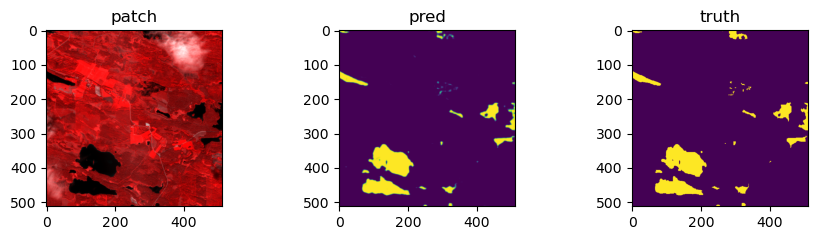

Ep100: tra-> Loss:0.034,Oa:0.987,Miou:0.964,                                 time:5.3s


In [ ]:
if __name__ == '__main__':
    metrics = train_loops(model=model,  
                    epoches=500,   
                    loss_fn=bce_loss,   
                    optimizer=optimizer,  
                    tra_loader=tra_loader,   
                    val_loader=val_loader,   
                    # lr_scheduler=lr_scheduler,   
                    device=device) 



In [ ]:
# torch.save(model.state_dict(), f'model/trained/{model_name}_.pth')
# ## metrics saving
# path_metrics = f'model/trained/{model_name}_training_metrics.csv'
# metrics_df = pd.DataFrame(metrics)
# metrics_df.to_csv(path_metrics, index=False, sep=',')  
